# Part 2: Cell-Type Classification from scRNA-seq

Classify 700 PBMCs into 10 immune cell types from 765-gene expression profiles.

**Pipeline:** load data → one-hot encode labels → 80/20 shuffle split → standardize →
multinomial logistic regression (primary) vs. random forest (baseline) → evaluate with
cross-validation, per-class metrics, confusion matrix, one-vs-rest ROC, and coefficient analysis.

Run from the `notebooks/` directory. Data is read from `../data/`; figures are written to `../figures/`.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_curve, auc)

warnings.filterwarnings("ignore")

DATA_DIR = "../data"
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Load and merge data

`processed_counts.csv` holds normalized log counts (rows = cells, columns = 765 genes).
`labels.csv` maps each cell barcode to a cell-type label assigned by the original researchers.

In [2]:
counts_pd = pd.read_csv(os.path.join(DATA_DIR, "processed_counts.csv"), index_col=0)
labels_pd = pd.read_csv(os.path.join(DATA_DIR, "labels.csv"), index_col="index")

df = counts_pd.merge(labels_pd, left_index=True, right_index=True).dropna()
df = df.rename(columns={"bulk_labels": "cell type"})
print(f"Merged dataset: {df.shape[0]} cells x {df.shape[1] - 1} genes")
df.head()

Merged dataset: 700 cells x 765 genes


,HES4,TNFRSF4,SSU72,PARK7,RBP7,SRM,MAD2L2,AGTRAP,TNFRSF1B,EFHD2,NECAP2,HP1BP3,C1QA,C1QB,HNRNPR,GALE,STMN1,CD52,FGR,ATPIF1,SESN2,EIF3I,LCK,MARCKSL1,SFPQ,PSMB2,MEAF6,NDUFS5,CAP1,SMAP2,C1orf228,PRDX1,TMEM69,SCP2,MAGOH,JAK1,CCBL2,GBP2,CD53,DENND2D,...,ZNF600,ZNF524,CTD-3138B18.5,ATP6V1E1,BID,MRPL40,UFD1L,COMT,DGCR6L,SDF2L1,IGLL5,IGLL1,CHCHD10,SMARCB1,MIF,ASCC2,PIK3IP1,HMOX1,EIF3D,IL2RB,LGALS2,EIF3L,ADSL,RBX1,TTC38,TYMP,CCT8,SOD1,PAXBP1,ATP5O,MRPS6,TTC3,U2AF1,CSTB,SUMO3,ITGB2,S100B,PRMT2,MT-ND3,cell type
AAAGCCTGGCTAAC-1,-0.326,-0.191,-0.728,-0.301,3.386,-0.531,2.016,3.377,4.841,-0.525,-0.525,1.804,0.578,-0.198,1.266,-0.192,-0.307,0.048,-0.606,0.478,-0.07,-0.864,-0.534,-0.504,-0.509,-0.727,-0.646,0.336,-0.017,4.381,-0.251,0.235,-0.252,-0.701,-0.537,-0.684,-0.244,-0.421,0.575,-0.375,...,-0.109,-0.402,-0.122,-0.583,-0.690,-0.487,-0.582,-0.630,-0.507,0.697,-0.133,-0.062,1.777,0.948,0.436,-0.345,-0.418,0.652,0.351,-0.196,-0.413,-0.323,-0.491,-0.719,-0.205,-0.092,-0.694,-0.070,-0.116,-0.146,-0.532,-0.341,0.303,1.404,4.294,0.519,-0.21,-0.636,4.011,CD14+ Monocyte
AAATTCGATGCACA-1,1.171,-0.191,0.795,-1.200,-0.174,-0.531,1.889,-0.486,-0.459,-0.525,1.287,-0.420,0.954,2.367,1.170,-0.192,-0.307,0.266,0.629,-0.802,-0.07,-0.864,-0.534,0.873,-0.509,0.645,-0.646,0.274,0.856,1.845,-0.251,-0.796,-0.252,-0.701,1.581,-0.684,-0.244,-0.421,-0.282,-0.375,...,-0.109,-0.402,-0.122,-0.583,2.992,1.327,-0.582,0.991,-0.507,0.636,-0.133,-0.062,-0.687,-0.497,0.373,-0.345,-0.418,-0.366,1.496,-0.196,-0.413,0.478,-0.491,-0.719,-0.205,1.089,-0.694,-0.120,-0.116,-1.136,-0.532,-0.341,-0.905,2.849,-0.585,1.172,-0.21,2.630,-0.490,Dendritic
AACACGTGGTCTTT-1,-0.326,-0.191,0.483,-1.200,-0.174,-0.531,-0.451,0.971,-0.459,2.286,-0.525,1.258,-0.310,-0.198,-0.602,-0.192,-0.307,-0.462,1.358,-0.802,-0.07,0.205,-0.534,-0.504,-0.509,0.364,-0.646,-0.881,-0.256,-0.445,-0.251,-0.796,-0.252,0.480,2.831,1.528,-0.244,0.816,-0.440,1.583,...,-0.109,-0.402,-0.122,-0.583,-0.690,-0.487,-0.582,-0.630,-0.507,-0.502,-0.133,-0.062,-0.687,-0.497,-0.782,-0.345,-0.418,-0.366,0.037,5.397,-0.413,0.131,1.310,-0.719,-0.205,-0.733,1.747,0.428,-0.116,-1.136,2.606,-0.341,-0.905,-0.455,-0.585,0.722,-0.21,0.663,-0.490,CD56+ NK
AAGTGCACGTGCTA-1,-0.326,-0.191,1.134,-0.157,-0.174,-0.531,-0.451,-0.486,-0.459,-0.525,-0.525,9.900,-0.310,-0.198,1.565,-0.192,2.270,1.258,-0.606,-0.802,-0.07,-0.864,0.741,-0.504,2.193,2.630,1.627,-0.881,-0.990,-0.445,-0.251,-0.796,-0.252,1.114,-0.537,-0.684,-0.244,1.481,2.728,-0.375,...,-0.109,-0.402,-0.122,-0.583,-0.690,-0.487,-0.582,-0.630,-0.507,-0.502,-0.133,-0.062,-0.687,-0.497,-0.782,-0.345,-0.418,-0.366,2.036,-0.196,-0.413,-0.180,-0.491,-0.719,-0.205,-0.733,-0.694,1.221,-0.116,1.161,-0.532,-0.341,-0.905,-0.119,-0.585,0.766,-0.21,-0.636,-0.490,CD4+/CD25 T Reg
ACACGAACGGAGTG-1,-0.326,-0.191,-0.728,-0.607,-0.174,-0.531,-0.451,0.787,-0.459,1.932,-0.525,1.046,-0.310,-0.198,0.630,-0.192,-0.307,-0.546,1.110,1.730,-0.07,1.005,-0.534,-0.504,-0.509,-0.727,-0.646,-0.881,0.293,-0.445,-0.251,-0.796,-0.252,1.363,2.407,0.283,-0.244,-0.421,-0.518,-0.375,...,-0.109,-0.402,-0.122,-0.583,-0.690,-0.487,-0.582,-0.630,-0.507,-0.502,-0.133,-0.062,-0.687,-0.497,0.824,-0.345,-0.418,0.306,-0.926,-0.196,3.847,1.138,-0.491,0.213,-0.205,-0.310,-0.694,-1.048,-0.116,-1.136,0.839,1.679,-0.108,-0.534,-0.585,-0.007,-0.21,-0.636,-0.490,Dendritic


## 2. One-hot encode labels, shuffle, and split (80/20)

Features and labels are shuffled with the same permutation so they stay aligned.

In [3]:
categories = df["cell type"].unique()
categories_list = list(categories)
print("Cell types:", categories_list)
print("Number of classes:", len(categories_list))

y = np.zeros((len(df), len(categories)))
for i in range(len(df)):
    cell_type = df.iloc[i]["cell type"]
    pos = np.where(categories == cell_type)[0]
    y[i, pos] = 1

X = df.drop("cell type", axis=1).values

np.random.seed(100)
permutation = np.random.permutation(len(X))
X, y = X[permutation], y[permutation]

X_train, y_train = X[:int(len(X) * 0.8)], y[:int(len(y) * 0.8)]
X_test, y_test = X[int(len(X) * 0.8):], y[int(len(y) * 0.8):]

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")

Cell types: ['CD14+ Monocyte', 'Dendritic', 'CD56+ NK', 'CD4+/CD25 T Reg', 'CD19+ B', 'CD8+ Cytotoxic T', 'CD4+/CD45RO+ Memory', 'CD8+/CD45RA+ Naive Cytotoxic', 'CD4+/CD45RA+/CD25- Naive T', 'CD34+']
Number of classes: 10
Train: (560, 765)  |  Test: (140, 765)


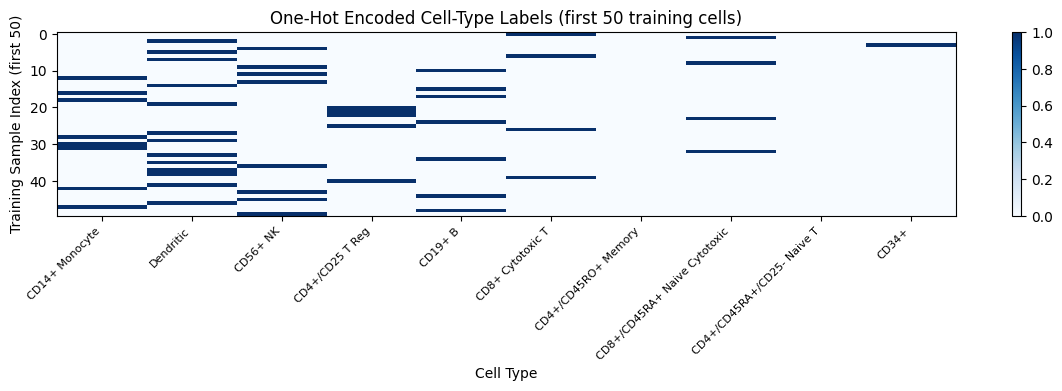

In [4]:
plt.figure(figsize=(12, 4), dpi=150)
plt.imshow(y_train[:50], aspect="auto", cmap="Blues")
plt.colorbar()
plt.xlabel("Cell Type")
plt.ylabel("Training Sample Index (first 50)")
plt.title("One-Hot Encoded Cell-Type Labels (first 50 training cells)")
plt.xticks(ticks=range(len(categories_list)), labels=categories_list,
           rotation=45, ha="right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "onehot.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. Preprocess

Integer class indices are derived from the one-hot labels, and features are standardized
(scaler fit on the training set only) so the L2 penalty treats all genes uniformly.

In [5]:
y_train_int = np.argmax(y_train, axis=1)
y_test_int = np.argmax(y_test, axis=1)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Classes: {categories_list}")
print(f"Train: {X_train.shape[0]} cells | Test: {X_test.shape[0]} cells | Features: {X_train.shape[1]}")

Classes: ['CD14+ Monocyte', 'Dendritic', 'CD56+ NK', 'CD4+/CD25 T Reg', 'CD19+ B', 'CD8+ Cytotoxic T', 'CD4+/CD45RO+ Memory', 'CD8+/CD45RA+ Naive Cytotoxic', 'CD4+/CD45RA+/CD25- Naive T', 'CD34+']
Train: 560 cells | Test: 140 cells | Features: 765


## 4. Train models

- **Primary:** multinomial logistic regression, L2 penalty (C = 1.0), `lbfgs` solver, on standardized features.
- **Baseline:** random forest (200 trees) on unscaled features.

In [6]:
print("Training Logistic Regression (multinomial, L2, C=1)...")
clf = LogisticRegression(C=1.0, max_iter=3000, solver="lbfgs", random_state=42)
clf.fit(X_train_s, y_train_int)

train_acc = accuracy_score(y_train_int, clf.predict(X_train_s))
test_acc = accuracy_score(y_test_int, clf.predict(X_test_s))
print(f"Train accuracy: {train_acc:.4f}")
print(f"Test  accuracy: {test_acc:.4f}")

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train_int)
rf_acc = accuracy_score(y_test_int, rf.predict(X_test))
print(f"\nBaseline RF accuracy: {rf_acc:.4f}")

Training Logistic Regression (multinomial, L2, C=1)...
Train accuracy: 1.0000
Test  accuracy: 0.8714

Baseline RF accuracy: 0.8214


## 5. Cross-validation (training set)

A single 140-cell test split is small and noisy, so 5-fold stratified cross-validation on the
training set gives a second estimate of generalization.

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(clf, X_train_s, y_train_int, cv=skf, scoring="accuracy")
print(f"5-fold CV: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

5-fold CV: 0.8107 +/- 0.0331


## 6. Test-set evaluation

Per-class precision/recall/F1, confusion matrix, and one-vs-rest ROC curves.

In [8]:
y_pred = clf.predict(X_test_s)
print("Classification Report (test set):\n")
print(classification_report(y_test_int, y_pred, target_names=categories_list, zero_division=0))

Classification Report (test set):

                              precision    recall  f1-score   support

              CD14+ Monocyte       0.84      0.90      0.87        30
                   Dendritic       0.94      0.94      0.94        50
                    CD56+ NK       1.00      0.67      0.80         6
             CD4+/CD25 T Reg       0.60      0.90      0.72        10
                     CD19+ B       1.00      0.87      0.93        15
            CD8+ Cytotoxic T       0.79      0.79      0.79        14
         CD4+/CD45RO+ Memory       1.00      1.00      1.00         1
CD8+/CD45RA+ Naive Cytotoxic       0.88      0.78      0.82         9
  CD4+/CD45RA+/CD25- Naive T       0.00      0.00      0.00         2
                       CD34+       1.00      1.00      1.00         3

                    accuracy                           0.87       140
                   macro avg       0.80      0.78      0.79       140
                weighted avg       0.87      0.87    

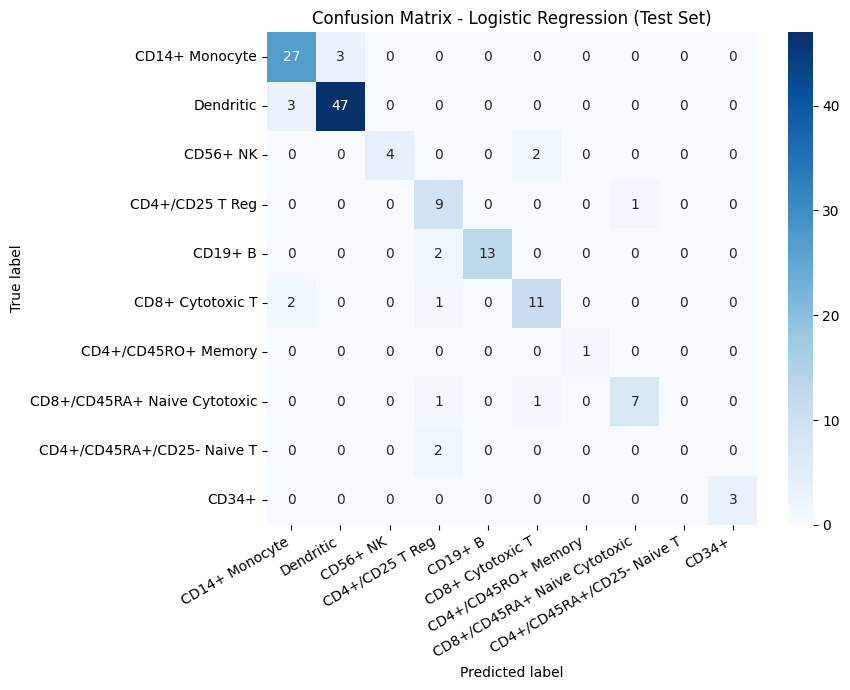

In [9]:
cm = confusion_matrix(y_test_int, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=categories_list, yticklabels=categories_list)
plt.title("Confusion Matrix - Logistic Regression (Test Set)")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

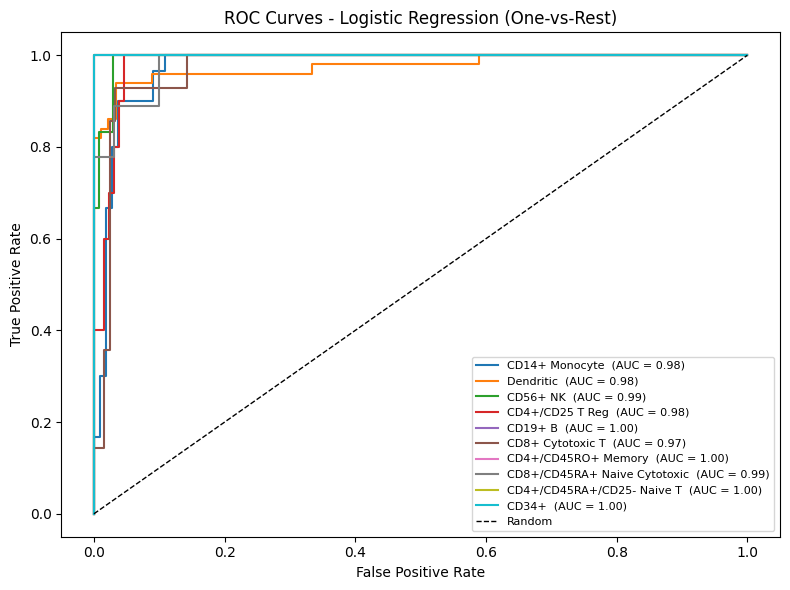

In [10]:
y_prob = clf.predict_proba(X_test_s)

fig, ax = plt.subplots(figsize=(8, 6))
for i, cls in enumerate(categories_list):
    fpr, tpr, _ = roc_curve(y_test[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{cls}  (AUC = {roc_auc:.2f})")

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves - Logistic Regression (One-vs-Rest)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "roc_curves.png"), dpi=150)
plt.show()

## 7. Interpretation: most discriminative genes

Mean absolute logistic regression coefficient per gene, averaged across the 10 classes.

Top 10 genes: ['CD8B', 'CCL5', 'GNLY', 'CD7', 'CD8A', 'GZMH', 'IL32', 'NEAT1', 'HCST', 'HIST1H4C']


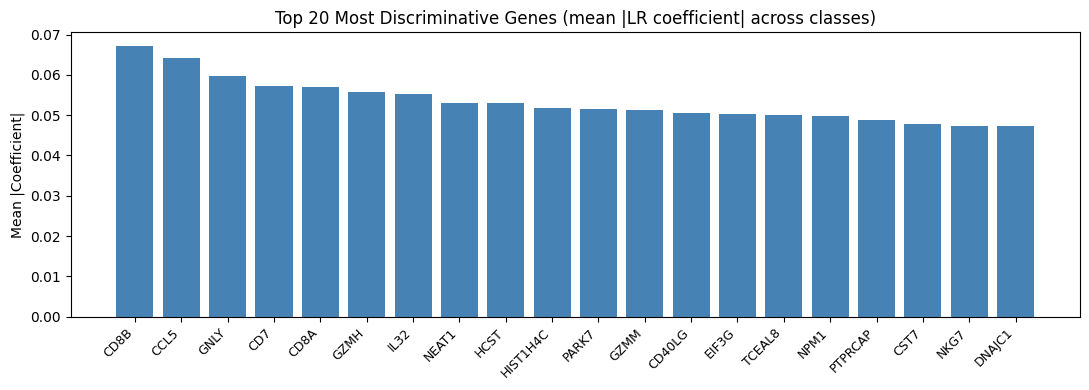

In [11]:
feature_names = df.drop("cell type", axis=1).columns.tolist()
coef_mean_abs = np.abs(clf.coef_).mean(axis=0)
top_idx = np.argsort(coef_mean_abs)[::-1][:20]

plt.figure(figsize=(11, 4))
plt.bar(range(20), coef_mean_abs[top_idx], color="steelblue")
plt.xticks(range(20), [feature_names[i] for i in top_idx],
           rotation=45, ha="right", fontsize=9)
plt.title("Top 20 Most Discriminative Genes (mean |LR coefficient| across classes)")
plt.ylabel("Mean |Coefficient|")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "feature_importance.png"), dpi=150)
plt.show()

print("Top 10 genes:", [feature_names[i] for i in top_idx[:10]])

## 8. Model comparison

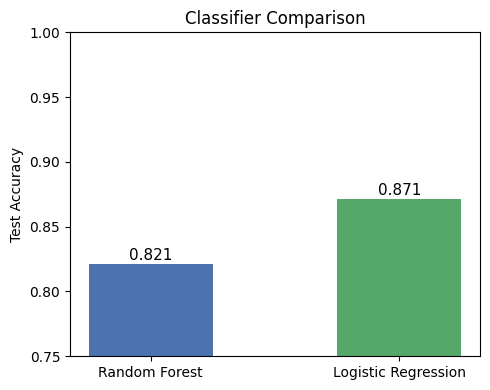

In [12]:
methods = ["Random Forest", "Logistic Regression"]
accs = [rf_acc, test_acc]

plt.figure(figsize=(5, 4))
bars = plt.bar(methods, accs, color=["#4C72B0", "#55A868"], width=0.5)
plt.ylim(0.75, 1.0)
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
             f"{acc:.3f}", ha="center", fontsize=11)
plt.ylabel("Test Accuracy")
plt.title("Classifier Comparison")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "classifier_comparison.png"), dpi=150)
plt.show()

## Summary and limitations

Logistic regression on standardized expression reached the highest held-out accuracy and the most
interpretable model (top genes are canonical T/NK markers). Caveats worth keeping in mind:

- **Class imbalance:** rare classes (e.g., CD4+/CD45RA+/CD25- Naive T, 8 cells total) have only a
  handful of test examples, so their per-class metrics are very noisy.
- **Generalization gap:** training accuracy is 100%, versus a lower cross-validated and test accuracy.
- **Similar T-cell subtypes** account for most errors.
- **Next steps:** stratified splitting, class weighting, hyperparameter search over `C`, and
  classification on the autoencoder latent space from Part 1.